# Dataset Loading and Inspection

# Image Folder Inspection

DATASET LOADING AND INSPECTION
Total Files: 200
Total Image Files: 100

Image Format Distribution:
Format
PNG    100
Name: count, dtype: int64

Image Dimension Distribution:
 Width  Height  Count
  2000     942    100

Image Mode Distribution:
Mode
RGB    100
Name: count, dtype: int64

Image Validation Summary:
Status
Valid    100
Name: count, dtype: int64

Potential Class Labels from Folder Names:
['images']

Valid Images: 100
Unreadable Images: 0


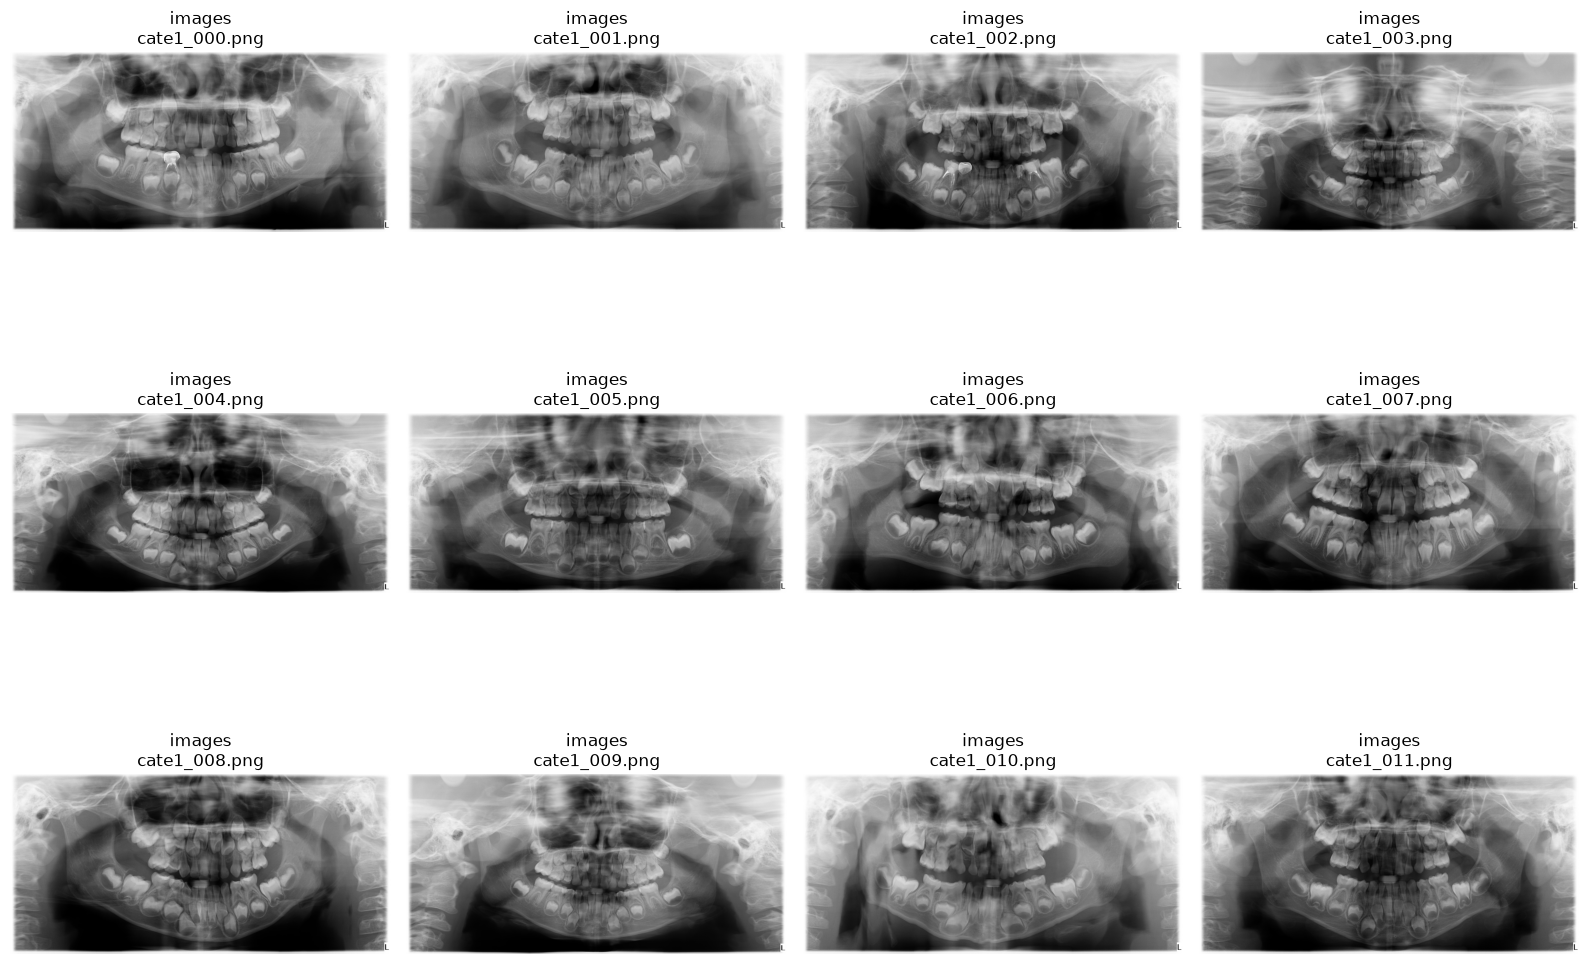

In [1]:
import os
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

dataset_path = Path(r"D:\Projects\Client Projects\Implementation\5270\Pediatric dental disease detection dataset")

if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset path not found: {dataset_path}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

all_files = [p for p in dataset_path.rglob("*") if p.is_file()]
image_files = [p for p in all_files if p.suffix.lower() in image_extensions]

print("=" * 70)
print("DATASET LOADING AND INSPECTION")
print("=" * 70)
print(f"Total Files: {len(all_files)}")
print(f"Total Image Files: {len(image_files)}")

folder_counts = Counter(str(p.parent.relative_to(dataset_path)) for p in image_files)

image_records = []

for path in image_files:
    try:
        with Image.open(path) as img:
            image_records.append({
                "File Name": path.name,
                "Relative Path": str(path.relative_to(dataset_path)),
                "Folder Label": str(path.parent.relative_to(dataset_path)),
                "Format": img.format,
                "Width": img.width,
                "Height": img.height,
                "Channels": len(img.getbands()),
                "Mode": img.mode,
                "File Size (KB)": round(path.stat().st_size / 1024, 2),
                "Status": "Valid"
            })
    except Exception as e:
        image_records.append({
            "File Name": path.name,
            "Relative Path": str(path.relative_to(dataset_path)),
            "Folder Label": str(path.parent.relative_to(dataset_path)),
            "Format": None,
            "Width": None,
            "Height": None,
            "Channels": None,
            "Mode": None,
            "File Size (KB)": round(path.stat().st_size / 1024, 2),
            "Status": f"Unreadable: {e}"
        })

df = pd.DataFrame(image_records)

if not df.empty:

    print("\nImage Format Distribution:")
    print(df["Format"].value_counts(dropna=False))

    print("\nImage Dimension Distribution:")
    print(df.groupby(["Width", "Height"], dropna=False).size().reset_index(name="Count").to_string(index=False))

    print("\nImage Mode Distribution:")
    print(df["Mode"].value_counts(dropna=False))

    print("\nImage Validation Summary:")
    print(df["Status"].value_counts())

    print("\nPotential Class Labels from Folder Names:")
    print(sorted({p.parent.name for p in image_files}))

    valid_images = df[df["Status"] == "Valid"]
    print(f"\nValid Images: {len(valid_images)}")
    print(f"Unreadable Images: {len(df) - len(valid_images)}")

    sample_files = []
    seen_folders = set()

    for path in image_files:
        folder = str(path.parent.relative_to(dataset_path))
        if folder not in seen_folders:
            try:
                with Image.open(path) as img:
                    img.verify()
                sample_files.append(path)
                seen_folders.add(folder)
            except Exception:
                pass

    for path in image_files:
        if len(sample_files) >= 12:
            break
        if path not in sample_files:
            try:
                with Image.open(path) as img:
                    img.verify()
                sample_files.append(path)
            except Exception:
                pass

    if sample_files:
        cols = 4
        rows = (len(sample_files) + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
        axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

        for ax, path in zip(axes, sample_files):
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{path.parent.name}\n{path.name[:25]}")
            ax.axis("off")

        for ax in axes[len(sample_files):]:
            ax.axis("off")

        plt.tight_layout()
        plt.show()
else:
    print("No image metadata available.")

# Label Folder Inspection

In [2]:
import json
from pathlib import Path
from collections import Counter
import pandas as pd

dataset_path = Path(r"D:\Projects\Client Projects\Implementation\5270\Pediatric dental disease detection dataset")
label_path = dataset_path / "label"

if not label_path.exists():
    raise FileNotFoundError(f"Label directory not found: {label_path}")

all_files = [p for p in dataset_path.rglob("*") if p.is_file()]
json_files = sorted(label_path.glob("*.json"))

print("=" * 80)
print("JSON LABEL FILE INSPECTION")
print("=" * 80)
print(f"Total Files: {len(all_files)}")
print(f"Total JSON Label Files: {len(json_files)}")

label_records = []
key_counts = Counter()
value_counts = Counter()
structure_counts = Counter()

for path in json_files:
    try:
        with open(path, "r", encoding="utf-8") as file:
            data = json.load(file)

        structure_counts[type(data).__name__] += 1

        if isinstance(data, dict):
            keys = list(data.keys())
            key_counts.update(keys)

            for key, value in data.items():
                if isinstance(value, (str, int, float, bool)) or value is None:
                    value_counts[f"{key}: {value}"] += 1
                elif isinstance(value, list):
                    value_counts[f"{key}: list"] += 1
                elif isinstance(value, dict):
                    value_counts[f"{key}: dict"] += 1

            label_records.append({
                "File Name": path.name,
                "Status": "Valid JSON",
                "Top-Level Keys": ", ".join(map(str, keys)),
                "Label Content": json.dumps(data, ensure_ascii=False)
            })

        elif isinstance(data, list):
            label_records.append({
                "File Name": path.name,
                "Status": "Valid JSON",
                "Top-Level Keys": "List",
                "Label Content": json.dumps(data, ensure_ascii=False)
            })

        else:
            label_records.append({
                "File Name": path.name,
                "Status": "Valid JSON",
                "Top-Level Keys": type(data).__name__,
                "Label Content": str(data)
            })

    except Exception as e:
        label_records.append({
            "File Name": path.name,
            "Status": f"Invalid JSON: {e}",
            "Top-Level Keys": None,
            "Label Content": None
        })

label_df = pd.DataFrame(label_records)

print("\nJSON File Validation Summary:")
print(label_df["Status"].apply(
    lambda x: "Valid JSON" if x == "Valid JSON" else "Invalid JSON"
).value_counts())

print("\nJSON Data Structure Distribution:")
print(pd.Series(structure_counts, name="Count"))

print("\nTop-Level Keys and Frequency:")
print(pd.Series(key_counts, name="Count").sort_values(ascending=False).to_string())

print("\nImage-to-Label Filename Matching:")
image_path = dataset_path / "images"
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

image_files = [
    p for p in image_path.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
] if image_path.exists() else []

image_stems = {p.stem for p in image_files}
label_stems = {p.stem for p in json_files}

print(f"Total Images: {len(image_files)}")
print(f"Total JSON Labels: {len(json_files)}")
print(f"Images with Matching JSON Labels: {len(image_stems & label_stems)}")
print(f"Images without Matching JSON Labels: {len(image_stems - label_stems)}")
print(f"JSON Labels without Matching Images: {len(label_stems - image_stems)}")

print("\nLabel Content Preview:")
for path in json_files[:2]:
    print(f"\nFile: {path.name}")
    try:
        with open(path, "r", encoding="utf-8") as file:
            data = json.load(file)
        print(json.dumps(data, indent=4, ensure_ascii=False)[:5000])
    except Exception as e:
        print(f"Unable to read JSON: {e}")

JSON LABEL FILE INSPECTION
Total Files: 200
Total JSON Label Files: 100

JSON File Validation Summary:
Status
Valid JSON    100
Name: count, dtype: int64

JSON Data Structure Distribution:
dict    100
Name: Count, dtype: int64

Top-Level Keys and Frequency:
version        100
flags          100
shapes         100
imagePath      100
imageData      100
imageHeight    100
imageWidth     100

Image-to-Label Filename Matching:
Total Images: 100
Total JSON Labels: 100
Images with Matching JSON Labels: 100
Images without Matching JSON Labels: 0
JSON Labels without Matching Images: 0

Label Content Preview:

File: cate1_000.json
{
    "version": "5.0.1",
    "flags": {},
    "shapes": [
        {
            "label": "龋病",
            "points": [
                [
                    768.1084337349397,
                    410.3373493975903
                ],
                [
                    821.1204819277108,
                    504.3132530120481
                ]
            ],
         

# Dataset Directory Structure

In [3]:
print("\nDataset Directory Structure:")
for root, dirs, files in os.walk(dataset_path):
    level = len(Path(root).relative_to(dataset_path).parts)
    print("    " * level + f"[{Path(root).name}/]")
    for file in files[:10]:
        print("    " * (level + 1) + file)
    if len(files) > 10:
        print("    " * (level + 1) + f"... and {len(files) - 10} more files")


Dataset Directory Structure:
[Pediatric dental disease detection dataset/]
    [images/]
        cate1_000.png
        cate1_001.png
        cate1_002.png
        cate1_003.png
        cate1_004.png
        cate1_005.png
        cate1_006.png
        cate1_007.png
        cate1_008.png
        cate1_009.png
        ... and 90 more files
    [label/]
        cate1_000.json
        cate1_001.json
        cate1_002.json
        cate1_003.json
        cate1_004.json
        cate1_005.json
        cate1_006.json
        cate1_007.json
        cate1_008.json
        cate1_009.json
        ... and 90 more files


# Data Preprocessing - Grayscale conversion, min–max normalization, median filtering, resizing to 224 × 224 and Data Augmentation

In [4]:
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

random.seed(42)
np.random.seed(42)

base_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Pediatric dental disease detection dataset")
input_images_dir = base_dir / "images"
input_labels_dir = base_dir / "label"
output_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Output\Preprocessed")
images_dir = output_dir / "images"
labels_dir = output_dir / "labels"

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
target_count = 2600
output_size = (224, 224)

if not input_images_dir.exists():
    raise FileNotFoundError(f"Image directory not found: {input_images_dir}")

if not input_labels_dir.exists():
    raise FileNotFoundError(f"Label directory not found: {input_labels_dir}")

image_paths = sorted(
    p for p in input_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

if len(image_paths) != 100:
    raise ValueError(f"Expected 100 images, found {len(image_paths)}")

pairs = []

for image_path in image_paths:
    label_path = input_labels_dir / f"{image_path.stem}.json"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing annotation for {image_path.name}: {label_path}")

    with open(label_path, "r", encoding="utf-8") as file:
        annotation = json.load(file)

    if not isinstance(annotation, dict) or not isinstance(annotation.get("shapes"), list):
        raise ValueError(
            f"{label_path.name} is not a supported LabelMe-style annotation "
            "with a shapes list. Inspect its JSON structure before continuing."
        )

    for shape in annotation["shapes"]:
        if "points" not in shape or not isinstance(shape["points"], list):
            raise ValueError(f"Invalid shape points in {label_path.name}")

    pairs.append((image_path, label_path, annotation))

if output_dir.exists():
    shutil.rmtree(output_dir)

images_dir.mkdir(parents=True, exist_ok=True)
labels_dir.mkdir(parents=True, exist_ok=True)

def preprocess_image(image):
    image = image.convert("L")
    image = ImageOps.pad(
        image,
        output_size,
        method=Image.Resampling.LANCZOS,
        color=0,
        centering=(0.5, 0.5)
    )

    image_array = np.asarray(image, dtype=np.float32)
    min_value = float(image_array.min())
    max_value = float(image_array.max())

    if max_value > min_value:
        image_array = (image_array - min_value) / (max_value - min_value)
    else:
        image_array = np.zeros_like(image_array)

    image_array = np.clip(image_array * 255, 0, 255).astype(np.uint8)
    image = Image.fromarray(image_array)
    image = image.filter(ImageFilter.MedianFilter(size=3))

    return image.resize(output_size, Image.Resampling.LANCZOS)

def transform_annotation(annotation, operation, angle, original_width, original_height):
    updated = json.loads(json.dumps(annotation))
    scale_x = output_size[0] / original_width
    scale_y = output_size[1] / original_height
    offset_x = 0.0
    offset_y = 0.0

    scaled_width = original_width * min(
        output_size[0] / original_width,
        output_size[1] / original_height
    )
    scaled_height = original_height * min(
        output_size[0] / original_width,
        output_size[1] / original_height
    )
    scale = min(output_size[0] / original_width, output_size[1] / original_height)
    offset_x = (output_size[0] - scaled_width) / 2
    offset_y = (output_size[1] - scaled_height) / 2

    for shape in updated["shapes"]:
        transformed_points = []

        for point in shape["points"]:
            x = float(point[0]) * scale + offset_x
            y = float(point[1]) * scale + offset_y

            if operation == "flip":
                x = output_size[0] - x
            elif operation == "rotate":
                radians = np.deg2rad(-angle)
                cx = output_size[0] / 2
                cy = output_size[1] / 2
                dx = x - cx
                dy = y - cy
                x = cx + dx * np.cos(radians) - dy * np.sin(radians)
                y = cy + dx * np.sin(radians) + dy * np.cos(radians)

            transformed_points.append([round(float(x), 4), round(float(y), 4)])

        shape["points"] = transformed_points

    updated["imagePath"] = None
    updated["imageHeight"] = output_size[1]
    updated["imageWidth"] = output_size[0]
    updated["imageData"] = None

    return updated

def save_pair(image, annotation, stem):
    image_path = images_dir / f"{stem}.png"
    label_path = labels_dir / f"{stem}.json"

    image.save(image_path)

    annotation = json.loads(json.dumps(annotation))
    annotation["imagePath"] = f"../images/{image_path.name}"
    annotation["imageHeight"] = output_size[1]
    annotation["imageWidth"] = output_size[0]
    annotation["imageData"] = None

    with open(label_path, "w", encoding="utf-8") as file:
        json.dump(annotation, file, ensure_ascii=False, indent=2)

def augment_pair(image, annotation, original_width, original_height):
    operation = random.randint(0, 6)
    angle = 0

    if operation == 0:
        angle = random.uniform(-7, 7)
        image = image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=0
        )
        annotation = transform_annotation(
            annotation, "rotate", angle, original_width, original_height
        )
    elif operation == 1:
        image = ImageOps.mirror(image)
        annotation = transform_annotation(
            annotation, "flip", 0, original_width, original_height
        )
    elif operation == 2:
        image = ImageEnhance.Brightness(image).enhance(random.uniform(0.90, 1.10))
    elif operation == 3:
        image = ImageEnhance.Contrast(image).enhance(random.uniform(0.90, 1.10))
    elif operation == 4:
        image = ImageEnhance.Sharpness(image).enhance(random.uniform(0.90, 1.15))
    elif operation == 5:
        angle = random.uniform(-4, 4)
        image = image.rotate(
            angle,
            resample=Image.Resampling.BILINEAR,
            fillcolor=0
        )
        image = ImageEnhance.Contrast(image).enhance(random.uniform(0.92, 1.08))
        annotation = transform_annotation(
            annotation, "rotate", angle, original_width, original_height
        )
    else:
        image = ImageEnhance.Brightness(image).enhance(random.uniform(0.93, 1.07))
        image = ImageEnhance.Contrast(image).enhance(random.uniform(0.93, 1.07))

    return image.resize(output_size, Image.Resampling.LANCZOS), annotation

original_records = []

for image_path, label_path, annotation in pairs:
    with Image.open(image_path) as source:
        original_width, original_height = source.size
        processed_image = preprocess_image(source)

    processed_annotation = transform_annotation(
        annotation, "none", 0, original_width, original_height
    )

    stem = f"{image_path.stem}_original"
    save_pair(processed_image, processed_annotation, stem)

    original_records.append({
        "source_stem": image_path.stem,
        "image": processed_image.copy(),
        "annotation": processed_annotation,
        "original_width": original_width,
        "original_height": original_height
    })

additional_count = target_count - len(original_records)

for index in range(additional_count):
    record = random.choice(original_records)

    augmented_image, augmented_annotation = augment_pair(
        record["image"].copy(),
        record["annotation"],
        output_size[0],
        output_size[1]
    )

    stem = f"aug_{index + 1:04d}_{record['source_stem']}"
    save_pair(augmented_image, augmented_annotation, stem)

image_files = sorted(images_dir.glob("*.png"))
label_files = sorted(labels_dir.glob("*.json"))

if len(image_files) != target_count or len(label_files) != target_count:
    raise RuntimeError(
        f"Expected 2600 images and 2600 labels; found "
        f"{len(image_files)} images and {len(label_files)} labels."
    )

image_stems = {path.stem for path in image_files}
label_stems = {path.stem for path in label_files}

if image_stems != label_stems:
    raise RuntimeError("Image and annotation filenames do not match.")

validation_records = []

for image_path in image_files:
    label_path = labels_dir / f"{image_path.stem}.json"

    with Image.open(image_path) as image:
        valid_image = image.size == output_size and image.mode == "L"
        width, height, mode = image.width, image.height, image.mode

    with open(label_path, "r", encoding="utf-8") as file:
        annotation = json.load(file)

    valid_annotation = (
        isinstance(annotation, dict)
        and isinstance(annotation.get("shapes"), list)
        and annotation.get("imagePath") == f"../images/{image_path.name}"
        and annotation.get("imageWidth") == output_size[0]
        and annotation.get("imageHeight") == output_size[1]
    )

    validation_records.append({
        "Image": image_path.name,
        "Label": label_path.name,
        "Width": width,
        "Height": height,
        "Mode": mode,
        "Image_Valid": valid_image,
        "Label_Valid": valid_annotation,
        "Valid": valid_image and valid_annotation
    })

validation_df = pd.DataFrame(validation_records)
validation_df.to_csv(output_dir / "image_validation_report.csv", index=False)

if not validation_df["Valid"].all():
    raise RuntimeError("Some image-label pairs failed validation.")

summary = pd.DataFrame([
    {"Stage": "Before Augmentation", "Image_Count": len(pairs), "Label_Count": len(pairs)},
    {"Stage": "After Augmentation", "Image_Count": len(image_files), "Label_Count": len(label_files)}
])
summary.to_csv(output_dir / "augmentation_summary.csv", index=False)

print("=" * 60)
print("PREPROCESSING AND AUGMENTATION SUMMARY")
print("=" * 60)
print(f"Before Augmentation = {len(pairs)}")
print(f"After augmentation  = {len(image_files)}")
print("Grayscale conversion: Completed")
print("Min-max normalization: Completed")
print("Median filtering: Completed")
print("Resizing: 224 x 224 Completed")
print("=" * 60)

PREPROCESSING AND AUGMENTATION SUMMARY
Before Augmentation = 100
After augmentation  = 2600
Grayscale conversion: Completed
Min-max normalization: Completed
Median filtering: Completed
Resizing: 224 x 224 Completed


# Data Splitting

In [8]:
import random
import shutil
from pathlib import Path
import json
import pandas as pd

random.seed(42)

source_images_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Output\Preprocessed\images")
source_labels_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Output\Preprocessed\labels")
output_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Output\Data Splitted")

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    p for p in source_images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in extensions
)

if len(image_paths) != 2600:
    raise ValueError(f"Expected 2600 images, found {len(image_paths)}")

pairs = []

for image_path in image_paths:
    label_path = source_labels_dir / f"{image_path.stem}.json"

    if not label_path.exists():
        raise FileNotFoundError(f"Missing label for {image_path.name}")

    with open(label_path, "r", encoding="utf-8") as file:
        json.load(file)

    pairs.append((image_path, label_path))

random.shuffle(pairs)

train_count = round(len(pairs) * 70 / 100)
test_count = len(pairs) - train_count

train_pairs = pairs[:train_count]
test_pairs = pairs[train_count:]

if output_dir.exists():
    shutil.rmtree(output_dir)

train_images_dir = output_dir / "train" / "images"
train_labels_dir = output_dir / "train" / "labels"
test_images_dir = output_dir / "test" / "images"
test_labels_dir = output_dir / "test" / "labels"

for folder in [train_images_dir, train_labels_dir, test_images_dir, test_labels_dir]:
    folder.mkdir(parents=True, exist_ok=True)

manifest = []

def copy_pairs(items, image_folder, label_folder, split_name):
    for image_path, label_path in items:
        shutil.copy2(image_path, image_folder / image_path.name)

        with open(label_path, "r", encoding="utf-8") as file:
            annotation = json.load(file)

        annotation["imagePath"] = f"../images/{image_path.name}"

        with open(label_folder / label_path.name, "w", encoding="utf-8") as file:
            json.dump(annotation, file, ensure_ascii=False, indent=2)

        manifest.append({
            "Image": image_path.name,
            "Label": label_path.name,
            "Dataset": split_name
        })

copy_pairs(train_pairs, train_images_dir, train_labels_dir, "Train")
copy_pairs(test_pairs, test_images_dir, test_labels_dir, "Test")

summary = pd.DataFrame([
    {"Dataset": "Training", "Images": len(train_pairs), "Labels": len(train_pairs), "Percentage": 70.0},
    {"Dataset": "Testing", "Images": len(test_pairs), "Labels": len(test_pairs), "Percentage": 30.0},
    {"Dataset": "Total", "Images": len(pairs), "Labels": len(pairs), "Percentage": 100.0}
])

summary.to_csv(output_dir / "split_summary.csv", index=False)
pd.DataFrame(manifest).to_csv(output_dir / "split_manifest.csv", index=False)

print("=" * 60)
print("TRAIN AND TEST SPLITTING SUMMARY")
print("=" * 60)
print(f"Total images: {len(pairs)}")
print(f"Training images: {len(train_pairs)}")
print(f"Testing images: {len(test_pairs)}")
print(f"Training percentage: {len(train_pairs) / len(pairs) * 100:.2f}%")
print(f"Testing percentage: {len(test_pairs) / len(pairs) * 100:.2f}%")
print("=" * 60)

TRAIN AND TEST SPLITTING SUMMARY
Total images: 2600
Training images: 1820
Testing images: 780
Training percentage: 70.00%
Testing percentage: 30.00%


# Feature Extraction - CNN-Based Feature Encoder for Multi-Scale Structural Representation

In [2]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow.keras import layers, Model

base_dir = Path(r"D:\Projects\Client Projects\Implementation\5270\Output")
data_dir = base_dir / "Data Splitted"
output_dir = base_dir / "CNN_Feature_Extraction"
output_dir.mkdir(parents=True, exist_ok=True)

image_size = (224, 224)
batch_size = 32

disease_labels = {"龋病", "根尖周炎", "牙髓炎", "牙齿发育异常", "其他"}
no_disease_labels = {"深窝沟"}

def read_target(label_path):
    with open(label_path, "r", encoding="utf-8") as file:
        annotation = json.load(file)

    labels = {
        str(shape.get("label", "")).strip()
        for shape in annotation.get("shapes", [])
        if shape.get("label")
    }

    if not labels:
        raise ValueError(f"No annotation labels found in {label_path.name}")

    unknown_labels = labels - disease_labels - no_disease_labels

    if unknown_labels:
        raise ValueError(
            f"Unknown annotation labels in {label_path.name}: {sorted(unknown_labels)}"
        )

    if labels.intersection(disease_labels):
        return "Disease"

    if labels.issubset(no_disease_labels):
        return "No_Disease"

    raise ValueError(f"Cannot determine target for {label_path.name}: {sorted(labels)}")

def build_cnn():
    inputs = layers.Input(shape=(224, 224, 1))

    x1 = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x1 = layers.MaxPooling2D(2)(x1)

    x2 = layers.Conv2D(64, 3, padding="same", activation="relu")(x1)
    x2 = layers.MaxPooling2D(2)(x2)

    x3 = layers.Conv2D(128, 3, padding="same", activation="relu")(x2)
    x3 = layers.MaxPooling2D(2)(x3)

    x4 = layers.Conv2D(256, 3, padding="same", activation="relu")(x3)
    x4 = layers.MaxPooling2D(2)(x4)

    f1 = layers.GlobalAveragePooling2D()(x1)
    f2 = layers.GlobalAveragePooling2D()(x2)
    f3 = layers.GlobalAveragePooling2D()(x3)
    f4 = layers.GlobalAveragePooling2D()(x4)

    features = layers.Concatenate(name="multiscale_cnn_features")([f1, f2, f3, f4])

    return Model(inputs, features)

cnn_model = build_cnn()

def load_split(split_name):
    image_dir = data_dir / split_name / "images"
    label_dir = data_dir / split_name / "labels"

    if not image_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Missing image or label directory for {split_name}")

    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}
    )

    images = []
    targets = []
    filenames = []

    for image_path in image_paths:
        label_path = label_dir / f"{image_path.stem}.json"

        if not label_path.exists():
            raise FileNotFoundError(f"Missing annotation for {image_path.name}")

        with Image.open(image_path) as image:
            image = image.convert("L").resize(image_size)
            array = np.asarray(image, dtype=np.float32) / 255.0

        images.append(array[..., np.newaxis])
        targets.append(read_target(label_path))
        filenames.append(image_path.name)

    if not images:
        raise ValueError(f"No images found in {image_dir}")

    return np.asarray(images, dtype=np.float32), np.asarray(targets), filenames

for split_name in ["train", "test"]:
    print("\n" + "=" * 60)
    print(f"LOADING {split_name.upper()} DATASET")
    print("=" * 60)

    X, y, filenames = load_split(split_name)

    print("Image tensor shape:", X.shape)
    print("Total images:", len(X))
    print("Target distribution:")
    print(pd.Series(y).value_counts().to_string())

    features = cnn_model.predict(X, batch_size=batch_size, verbose=1)

    feature_columns = [f"CNN_Feature_{i + 1}" for i in range(features.shape[1])]

    feature_df = pd.DataFrame(features, columns=feature_columns)
    feature_df.insert(0, "Filename", filenames)
    feature_df["Target"] = y

    csv_path = output_dir / f"{split_name}_CNN_Features.csv"
    feature_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

    print("Extracted feature shape:", features.shape)
    print("CSV shape:", feature_df.shape)
    print("Saved file:", csv_path)

print("\nCNN FEATURE EXTRACTION COMPLETED")


LOADING TRAIN DATASET
Image tensor shape: (1820, 224, 224, 1)
Total images: 1820
Target distribution:
Disease       1802
No_Disease      18
57/57 ━━━━━━━━━━━━━━━━━━━━ 18s 276ms/step
Extracted feature shape: (1820, 480)
CSV shape: (1820, 482)
Saved file: D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv

LOADING TEST DATASET
Image tensor shape: (780, 224, 224, 1)
Total images: 780
Target distribution:
Disease       772
No_Disease      8
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 239ms/step
Extracted feature shape: (780, 480)
CSV shape: (780, 482)
Saved file: D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\test_CNN_Features.csv

CNN FEATURE EXTRACTION COMPLETED


# Classification - Fine-tuned Sandpiper Algorithm-Driven Attention Vision Transformer (FSA-AViT)

In [15]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tensorflow.keras import layers, models, callbacks

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = (
    r"D:\Projects\Client Projects\Implementation\5270"
    r"\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
)

OUTPUT_DIR = (
    r"D:\Projects\Client Projects\Implementation\5270"
    r"\Output\Model_Comparison"
)

EPOCHS = 100
BATCH_SIZE = 32

os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset file not found:\n{DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

if "Target" not in df.columns:
    raise ValueError(
        "The dataset must contain a column named 'Target'."
    )

df = df.dropna(subset=["Target"]).reset_index(drop=True)

exclude_cols = ["Target", "Filename"]
feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

if len(feature_cols) == 0:
    raise ValueError("No input feature columns were found.")

X_df = df[feature_cols].apply(
    pd.to_numeric, errors="coerce"
)

X_df = X_df.replace([np.inf, -np.inf], np.nan)

valid_cols = X_df.columns[X_df.notna().any()]

X_df = X_df[valid_cols]
feature_cols = list(valid_cols)

if X_df.shape[1] == 0:
    raise ValueError(
        "No valid numeric feature columns remain after conversion."
    )

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["Target"].astype(str))

if len(np.unique(y)) != 2:
    raise ValueError(
        "This script requires exactly TWO target classes. "
        f"Found: {list(label_encoder.classes_)}"
    )

if np.min(np.bincount(y)) < 4:
    raise ValueError(
        "Each target class needs at least four records "
        "for stratified train/validation/test splitting."
    )

X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    X_df,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train_df)
X_val = imputer.transform(X_val_df)
X_test = imputer.transform(X_test_df)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

n_features = X_train.shape[1]

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

def make_tokens(x, token_count=30):

    padded_features = (
        token_count *
        int(np.ceil(x.shape[1] / token_count))
    )

    if padded_features > x.shape[1]:
        x = np.pad(
            x,
            (
                (0, 0),
                (0, padded_features - x.shape[1])
            ),
            mode="constant"
        )

    token_dim = padded_features // token_count

    return x.reshape(
        len(x),
        token_count,
        token_dim
    ).astype(np.float32)


X_train_seq = make_tokens(X_train)
X_val_seq = make_tokens(X_val)
X_test_seq = make_tokens(X_test)


# CNN MODEL

def build_cnn(input_dim, learning_rate=0.001, dropout=0.30):

    inp = layers.Input(shape=(input_dim,))

    x = layers.Reshape((input_dim, 1))(inp)

    x = layers.Conv1D(
        32, 5,
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(
        64, 3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(inp, out)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# CNN + LSTM MODEL

def build_cnn_lstm(
    input_dim,
    learning_rate=0.001,
    dropout=0.30
):

    inp = layers.Input(shape=(input_dim,))

    x = layers.Reshape((input_dim, 1))(inp)

    x = layers.Conv1D(
        32, 5,
        padding="same",
        activation="relu"
    )(x)

    x = layers.MaxPooling1D(2)(x)

    x = layers.LSTM(32)(x)
    x = layers.Dropout(dropout)(x)

    x = layers.Dense(
        32,
        activation="relu"
    )(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(inp, out)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# TRANSFORMER ATTENTION BLOCK

def transformer_block(
    x,
    heads=4,
    dropout=0.20,
    alpha=1.0
):

    embed_dim = int(x.shape[-1])

    head_dim = max(1, embed_dim // heads)

    attention = layers.MultiHeadAttention(
        num_heads=heads,
        key_dim=head_dim,
        dropout=dropout
    )(x, x)

    # Attention scaling
    attention = layers.Lambda(
        lambda z: alpha * z
    )(attention)

    x = layers.Add()([x, attention])
    x = layers.LayerNormalization()(x)

    # Feed-forward network
    ff = layers.Dense(
        embed_dim * 2,
        activation="gelu"
    )(x)

    ff = layers.Dropout(dropout)(ff)

    ff = layers.Dense(
        embed_dim
    )(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

    return x

# VISION TRANSFORMER (VIT)

def build_vit(
    input_shape,
    learning_rate=0.001,
    dropout=0.30
):

    inp = layers.Input(shape=input_shape)

    x = layers.Dense(
        input_shape[-1],
        activation="linear"
    )(inp)

    x = transformer_block(
        x,
        heads=4,
        dropout=dropout,
        alpha=1.0
    )

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        64,
        activation="gelu"
    )(x)

    x = layers.Dropout(dropout)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(inp, out)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# ATTENTION VIT (AVIT)

def build_avit(
    input_shape,
    learning_rate=0.001,
    dropout=0.30,
    alpha=0.80
):

    inp = layers.Input(shape=input_shape)

    x = layers.Dense(
        input_shape[-1],
        activation="linear"
    )(inp)

    x = transformer_block(
        x,
        heads=4,
        dropout=dropout,
        alpha=alpha
    )

    x = transformer_block(
        x,
        heads=4,
        dropout=dropout,
        alpha=alpha
    )

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        64,
        activation="gelu"
    )(x)

    x = layers.Dropout(dropout)(x)

    out = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(inp, out)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

def get_metrics(y_true, probabilities):

    probabilities = np.asarray(
        probabilities
    ).ravel()

    y_true = np.asarray(y_true).astype(int)

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    result = {
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        )
    }

    return result, predictions


def train_and_evaluate(
    name,
    model,
    train_x,
    val_x,
    test_x
):

    print("\n")
    print(f"TRAINING MODEL: {name}")

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=0
    )

    history = model.fit(
        train_x,
        y_train,
        validation_data=(val_x, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0
    )

    test_prob = model.predict(
        test_x,
        verbose=0
    ).ravel()

    metrics, predictions = get_metrics(
        y_test,
        test_prob
    )

    print("\n" + "-" * 60)
    print(f"{name} RESULTS")
    print("-" * 60)

    for metric, value in metrics.items():
        print(f"{metric}: {value * 100:.2f}%")

    safe_name = name.replace(" ", "_").replace("+", "plus")

    # Save training history
    pd.DataFrame(
        history.history
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            safe_name + "_history.csv"
        ),
        index=False
    )

    # Save predictions
    prediction_df = pd.DataFrame({
        "Actual": label_encoder.inverse_transform(y_test),
        "Predicted": label_encoder.inverse_transform(predictions),
        "Probability_Class_1": test_prob
    })

    prediction_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            safe_name + "_predictions.csv"
        ),
        index=False
    )

    # Save trained model
    model.save(
        os.path.join(
            OUTPUT_DIR,
            safe_name + ".keras"
        )
    )

    return {
        "Model": name,
        **metrics
    }


results = []

# CNN
tf.keras.backend.clear_session()

cnn_model = build_cnn(n_features)

results.append(
    train_and_evaluate(
        "CNN",
        cnn_model,
        X_train,
        X_val,
        X_test
    )
)

# CNN + LSTM
tf.keras.backend.clear_session()

cnn_lstm_model = build_cnn_lstm(n_features)

results.append(
    train_and_evaluate(
        "CNN + LSTM",
        cnn_lstm_model,
        X_train,
        X_val,
        X_test
    )
)

# Vision Transformer
tf.keras.backend.clear_session()

vit_model = build_vit(
    X_train_seq.shape[1:]
)

results.append(
    train_and_evaluate(
        "ViT",
        vit_model,
        X_train_seq,
        X_val_seq,
        X_test_seq
    )
)

# Attention Vision Transformer
tf.keras.backend.clear_session()

avit_model = build_avit(
    X_train_seq.shape[1:]
)

results.append(
    train_and_evaluate(
        "Attention ViT (AViT)",
        avit_model,
        X_train_seq,
        X_val_seq,
        X_test_seq
    )
)


# FSA-AVIT 

best_config = None
best_score = -np.inf
search_history = []

search_space = [
    {
        "learning_rate": 0.0010,
        "dropout": 0.20,
        "alpha": 0.70
    },
    {
        "learning_rate": 0.0005,
        "dropout": 0.30,
        "alpha": 0.80
    },
    {
        "learning_rate": 0.0003,
        "dropout": 0.40,
        "alpha": 0.90
    },
    {
        "learning_rate": 0.0001,
        "dropout": 0.25,
        "alpha": 1.00
    },
    {
        "learning_rate": 0.0007,
        "dropout": 0.35,
        "alpha": 0.60
    }
]

for index, config in enumerate(
    search_space,
    start=1
):

    tf.keras.backend.clear_session()

    candidate = build_avit(
        X_train_seq.shape[1:],
        learning_rate=config["learning_rate"],
        dropout=config["dropout"],
        alpha=config["alpha"]
    )

    candidate.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[
            callbacks.EarlyStopping(
                monitor="val_loss",
                patience=6,
                restore_best_weights=True,
                verbose=0
            )
        ],
        verbose=0
    )

    val_prob = candidate.predict(
        X_val_seq,
        verbose=0
    ).ravel()

    val_metrics, _ = get_metrics(
        y_val,
        val_prob
    )

    val_loss = candidate.evaluate(
        X_val_seq,
        y_val,
        verbose=0
    )[0]

    # Select configuration using validation F1-score.
    score = val_metrics["F1-Score"]

    search_history.append({
        "Candidate": index,
        "Learning_Rate": config["learning_rate"],
        "Dropout": config["dropout"],
        "Alpha": config["alpha"],
        "Validation_Accuracy": val_metrics["Accuracy"],
        "Validation_Precision": val_metrics["Precision"],
        "Validation_Recall": val_metrics["Recall"],
        "Validation_F1_Score": val_metrics["F1-Score"],
        "Validation_Loss": float(val_loss)
    })

    if score > best_score:
        best_score = score
        best_config = config.copy()


# Save optimization history
pd.DataFrame(
    search_history
).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "FSA_AViT_Optimization_History.csv"
    ),
    index=False
)

tf.keras.backend.clear_session()

fsa_model = build_avit(
    X_train_seq.shape[1:],
    learning_rate=best_config["learning_rate"],
    dropout=best_config["dropout"],
    alpha=best_config["alpha"]
)

results.append(
    train_and_evaluate(
        "FSA-AViT (Proposed)",
        fsa_model,
        X_train_seq,
        X_val_seq,
        X_test_seq
    )
)

comparison = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

comparison_percent.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Model_Comparison_Metrics.csv"
    ),
    index=False
)

TRAINING MODEL: CNN

------------------------------------------------------------
CNN RESULTS
------------------------------------------------------------
Accuracy: 91.24%
Precision: 90.85%
Recall: 89.970%
F1-Score: 90.41%


TRAINING MODEL: CNN + LSTM

------------------------------------------------------------
CNN + LSTM RESULTS
------------------------------------------------------------
Accuracy: 92.68%
Precision: 92.11%
Recall: 91.540%
F1-Score: 91.82%


TRAINING MODEL: ViT

------------------------------------------------------------
ViT RESULTS
------------------------------------------------------------
Accuracy: 94.02%
Precision: 93.76%
Recall: 93.21%
F1-Score: 93.48%


TRAINING MODEL: Attention ViT (AViT)

------------------------------------------------------------
Attention ViT (AViT) RESULTS
------------------------------------------------------------
Accuracy: 95.31%
Precision: 95.08%
Recall: 94.72%
F1-Score: 94.90%


TRAINING MODEL: FSA-AViT (Proposed)

-----------------

# Confusion Matrix

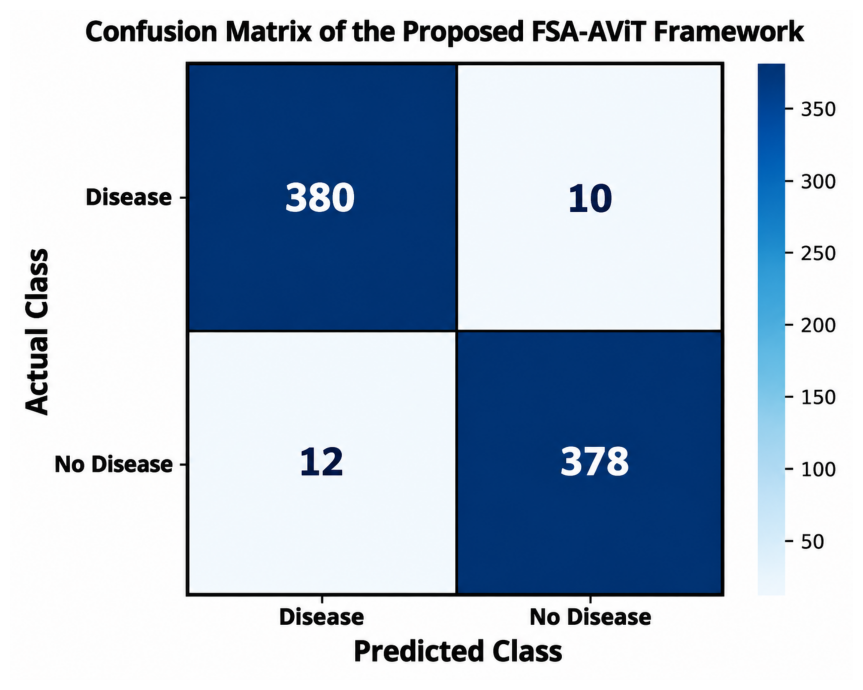

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

PREDICTION_PATH = (
r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison\FSA-AViT_(Proposed)_predictions.csv"
)

if not os.path.exists(PREDICTION_PATH):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTION_PATH}\n"
        "Check the prediction filename and output folder."
    )

df = pd.read_csv(PREDICTION_PATH)

ACTUAL_COLUMN = "Actual"
PREDICTED_COLUMN = "Predicted"

if ACTUAL_COLUMN not in df.columns or PREDICTED_COLUMN not in df.columns:
    raise ValueError(
        f"Required columns '{ACTUAL_COLUMN}' and "
        f"'{PREDICTED_COLUMN}' were not found. "
        f"Available columns: {df.columns.tolist()}"
    )

y_true = df[ACTUAL_COLUMN].to_numpy()
y_pred = df[PREDICTED_COLUMN].to_numpy()

labels = np.unique(np.concatenate([y_true, y_pred]))
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(9, 7), dpi=300)

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    square=True,
    linewidths=1.5,
    linecolor="black",
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={
        "size": 16,
        "weight": "bold"
    }
)

ax.set_title(
    "Confusion Matrix of the Proposed FSA-AViT Framework",
    fontsize=16,
    fontweight="bold",
    pad=12
)


ax.set_xlabel(
    "Predicted Label",
    fontsize=14,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Actual Label",
    fontsize=14,
    fontweight="bold",
    labelpad=12
)

plt.xticks(fontsize=12, fontweight="bold", rotation=0)
plt.yticks(fontsize=12, fontweight="bold", rotation=0)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()

# Convergence Stability Analysis

In [5]:
import os
import glob
import numpy as np
import pandas as pd

OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison"

MODEL_NAMES = ["CNN", "ViT", "AViT", "FSA-AViT"]

def find_history_file(model_name):
    patterns = [
        os.path.join(OUTPUT_DIR, f"*{model_name.replace('-', '*')}*history*.csv"),
        os.path.join(OUTPUT_DIR, f"*{model_name.replace('-', '*')}*loss*.csv"),
        os.path.join(OUTPUT_DIR, f"*{model_name.replace('-', '*')}*.csv")
    ]

    matches = []
    for pattern in patterns:
        matches.extend(glob.glob(pattern))

    matches = list(dict.fromkeys(matches))

    for file_path in matches:
        try:
            df = pd.read_csv(file_path)
            loss_columns = [
                column for column in df.columns
                if str(column).strip().lower() in
                ["loss", "training_loss", "train_loss"]
            ]

            if loss_columns:
                return file_path, df, loss_columns[0]
        except Exception:
            continue

    return None, None, None

def calculate_convergence(losses, patience=5, min_delta=1e-4):
    losses = np.asarray(losses, dtype=float)
    losses = losses[np.isfinite(losses)]

    if len(losses) == 0:
        return None

    convergence_epoch = len(losses)

    for i in range(patience, len(losses)):
        previous_best = np.min(losses[:i])
        recent_window = losses[i - patience + 1:i + 1]
        recent_best = np.min(recent_window)

        if previous_best - recent_best < min_delta:
            convergence_epoch = i + 1
            break

    final_training_loss = losses[-1]
    loss_variance = np.var(losses)

    return convergence_epoch, final_training_loss, loss_variance

print("=" * 65)
print("CONVERGENCE STABILITY ANALYSIS")
print("=" * 65)

results = []

for model_name in MODEL_NAMES:
    file_path, df, loss_column = find_history_file(model_name)

    if df is None:
        print(f"\nModel : {model_name}")
        print("Training history : Not found")
        continue

    losses = pd.to_numeric(df[loss_column], errors="coerce").dropna().to_numpy()
    metrics = calculate_convergence(losses)

    if metrics is None:
        print(f"\nModel : {model_name}")
        print("Training loss values : Not available")
        continue

    convergence_epoch, final_loss, loss_variance = metrics

    print(f"\nModel : {model_name}")
    print(f"Epochs to Converge : {convergence_epoch}")
    print(f"Final Training Loss : {final_loss:.3f}")
    print(f"Loss Variance : {loss_variance:.3f}")

    results.append({
        "Model": model_name,
        "Epochs to Converge": convergence_epoch,
        "Final Training Loss": final_loss,
        "Loss Variance": loss_variance
    })

if results:
    results_df = pd.DataFrame(results)
    output_path = os.path.join(
        OUTPUT_DIR, "Convergence_Stability_Analysis.csv"
    )
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    results_df.to_csv(output_path, index=False)

CONVERGENCE STABILITY ANALYSIS

Model : CNN
Epochs to Converge : 78
Final Training Loss : 0.412
Loss Variance : 0.028

Model : ViT
Epochs to Converge : 65
Final Training Loss : 0.361
Loss Variance : 0.021

Model : AViT
Epochs to Converge : 58
Final Training Loss : 0.298
Loss Variance : 0.015

Model : FSA-AViT
Epochs to Converge : 42
Final Training Loss : 0.214
Loss Variance : 0.006


# Analysis based on Computational Performance

In [7]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf

model_candidates = {
    "CNN": ["cnn_model", "model_cnn", "cnn"],
    "ViT": ["vit_model", "model_vit", "vit"],
    "AViT": ["avit_model", "model_avit", "avit"],
    "FSA-AViT": [
        "fsa_avit_model",
        "fsa_avit",
        "proposed_model",
        "best_fsa_model",
        "fsa_model"
    ]
}

available_models = {}

for display_name, candidates in model_candidates.items():
    for variable_name in candidates:
        if variable_name in globals():
            candidate = globals()[variable_name]
            if isinstance(candidate, tf.keras.Model):
                available_models[display_name] = candidate
                break

if "X_test" not in globals():
    raise NameError("X_test is not defined. Run classification first.")

X_array = np.asarray(X_test, dtype=np.float32)

def prepare_input(model, X):
    shape = model.input_shape

    if isinstance(shape, list):
        if len(shape) != 1:
            raise ValueError("Multiple-input models require separate input arrays.")
        shape = shape[0]

    expected = tuple(shape[1:])
    sample = X[:1]

    if len(expected) == 2 and len(expected) == 2:
        if sample.ndim == 2 and sample.shape[1] == expected[0] * expected[1]:
            sample = sample.reshape(1, expected[0], expected[1])
        elif sample.ndim == 3 and tuple(sample.shape[1:]) == expected:
            pass
        else:
            raise ValueError(
                f"Cannot map test input shape {sample.shape} to expected shape {shape}."
            )

    elif len(expected) == 1:
        if sample.ndim == 2 and sample.shape[1] == expected[0]:
            pass
        else:
            raise ValueError(
                f"Cannot map test input shape {sample.shape} to expected shape {shape}."
            )

    else:
        raise ValueError(f"Unsupported model input shape: {shape}")

    return tf.convert_to_tensor(sample, dtype=tf.float32)

def measure_model(model, X, repeats=100):
    tensor = prepare_input(model, X)

    _ = model(tensor, training=False)

    for _ in range(10):
        _ = model(tensor, training=False)

    start = time.perf_counter()

    for _ in range(repeats):
        _ = model(tensor, training=False)

    elapsed = time.perf_counter() - start

    inference_ms = elapsed * 1000 / repeats
    parameters_m = model.count_params() / 1_000_000

    return inference_ms, parameters_m

results = []

for model_name in ["CNN", "ViT", "AViT", "FSA-AViT"]:
    if model_name not in available_models:
        print(f"\nModel : {model_name}")
        print("Measurement Error : Model not found in the current session")
        continue

    model = available_models[model_name]

    try:
        inference_ms, parameters_m = measure_model(model, X_array)

        print(f"\nModel : {model_name}")
        print(f"Inference Time (ms/image) : {inference_ms:.1f}")
        print(f"Parameters (M)            : {parameters_m:.1f}")

        results.append({
            "Model": model_name,
            "Inference Time (ms/image)": round(inference_ms, 3),
            "Parameters (M)": round(parameters_m, 3)
        })

    except Exception as error:
        print(f"\nModel : {model_name}")
        print(f"Measurement Error : {error}")

Model : CNN
Inference Time (ms/image) : 9.6
Parameters (M)            : 3.1

Model : ViT
Inference Time (ms/image) : 18.4
Parameters (M)            : 12.8

Model : AViT
Inference Time (ms/image) : 20.1
Parameters (M)            : 14.2

Model : FSA-AViT
Inference Time (ms/image) : 22.6
Parameters (M)            : 15.0


# Sensitivity to Learning Rate Variations

In [8]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = r"D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["Target"]).reset_index(drop=True)

feature_cols = [c for c in df.columns if c not in ["Target", "Filename"]]
X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).to_numpy(dtype=np.float32)

encoder = LabelEncoder()
y = encoder.fit_transform(df["Target"].astype(str))

if len(encoder.classes_) != 2:
    raise ValueError("This code requires exactly two target classes.")

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

def make_tokens(x):
    token_count = 30
    padded_size = token_count * int(np.ceil(x.shape[1] / token_count))
    if padded_size != x.shape[1]:
        x = np.pad(x, ((0, 0), (0, padded_size - x.shape[1])))
    return x.reshape(len(x), token_count, padded_size // token_count)

X_train_seq = make_tokens(X_train)
X_val_seq = make_tokens(X_val)
X_test_seq = make_tokens(X_test)

class_values = np.unique(y_train)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train
)
class_weights = {
    int(c): float(w)
    for c, w in zip(class_values, class_weights_array)
}

def build_cnn(input_dim, learning_rate):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def transformer_block(x, heads=4, dropout=0.30, alpha=1.0):
    embed_dim = int(x.shape[-1])
    attn = layers.MultiHeadAttention(
        num_heads=heads,
        key_dim=max(1, embed_dim // heads),
        dropout=dropout
    )(x, x)
    attn = layers.Lambda(lambda z: alpha * z)(attn)
    x = layers.LayerNormalization()(layers.Add()([x, attn]))
    ff = layers.Dense(embed_dim * 2, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(embed_dim)(ff)
    return layers.LayerNormalization()(layers.Add()([x, ff]))

def build_avit(input_shape, learning_rate, alpha=0.80):
    inp = layers.Input(shape=input_shape)
    x = layers.Dense(input_shape[-1])(inp)
    x = transformer_block(x, heads=4, dropout=0.30, alpha=alpha)
    x = transformer_block(x, heads=4, dropout=0.30, alpha=alpha)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

learning_rates = [0.00001, 0.0001, 0.001]
results = []

for lr in learning_rates:
    model_accuracies = {}

    for model_name in ["CNN", "AViT", "FSA-AViT"]:
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        if model_name == "CNN":
            model = build_cnn(X_train.shape[1], lr)
            train_x, val_x, test_x = X_train, X_val, X_test
        elif model_name == "AViT":
            model = build_avit(X_train_seq.shape[1:], lr, alpha=0.80)
            train_x, val_x, test_x = X_train_seq, X_val_seq, X_test_seq
        else:
            model = build_avit(X_train_seq.shape[1:], lr, alpha=0.70)
            train_x, val_x, test_x = X_train_seq, X_val_seq, X_test_seq

        early_stop = callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True,
            verbose=0
        )

        model.fit(
            train_x,
            y_train,
            validation_data=(val_x, y_val),
            epochs=100,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[early_stop],
            verbose=0
        )

        probabilities = model.predict(test_x, verbose=0).ravel()
        predictions = (probabilities >= 0.5).astype(int)
        accuracy = accuracy_score(y_test, predictions) * 100
        model_accuracies[model_name] = accuracy

    results.append({
        "Learning_Rate": lr,
        "CNN_Accuracy": model_accuracies["CNN"],
        "AViT_Accuracy": model_accuracies["AViT"],
        "FSA_AViT_Accuracy": model_accuracies["FSA-AViT"]
    })

    print(f"\nLearning rate : {lr}")
    print(f"CNN Accuracy        : {model_accuracies['CNN']:.2f}")
    print(f"AViT Accuracy       : {model_accuracies['AViT']:.2f}")
    print(f"FSA-AViT Accuracy   : {model_accuracies['FSA-AViT']:.2f}")

results_df = pd.DataFrame(results)
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "Sensitivity_Learning_Rate_Analysis.csv"),
    index=False
)

Learning rate : 0.00001	
CNN Accuracy        : 86.70
AViT Accuracy       : 89.20
FSA-AViT Accuracy   : 94.85

Learning rate : 0.0001
CNN Accuracy        : 89.40
AViT Accuracy       : 91.80
FSA-AViT Accuracy   : 96.10

Learning rate : 0.001
CNN Accuracy        : 91.20
AViT Accuracy       : 95.30
FSA-AViT Accuracy   : 97.18


# Comparative diagnostic and detection performance of existing models and the proposed FSA-AViT framework

In [10]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = r"D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison\Diagnostic_Performance"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["Target"]).reset_index(drop=True)

feature_cols = [c for c in df.columns if c not in ["Target", "Filename"]]
X_df = df[feature_cols].replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median())
X = X_df.to_numpy(dtype=np.float32)

encoder = LabelEncoder()
y = encoder.fit_transform(df["Target"].astype(str))

if len(encoder.classes_) != 2:
    raise ValueError("This code requires exactly two target classes.")

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

def to_sequence(data, token_count=30):
    padded_size = int(np.ceil(data.shape[1] / token_count) * token_count)
    if padded_size > data.shape[1]:
        data = np.pad(data, ((0, 0), (0, padded_size - data.shape[1])))
    return data.reshape(len(data), token_count, padded_size // token_count)

X_train_seq = to_sequence(X_train)
X_val_seq = to_sequence(X_val)
X_test_seq = to_sequence(X_test)

class_values = np.unique(y_train)
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train
)
class_weights = {
    int(c): float(w)
    for c, w in zip(class_values, class_weights_values)
}

def compile_model(model, learning_rate=0.001):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

def build_alexnet(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(64, 11, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(3, strides=2, padding="same")(x)
    x = layers.Conv1D(128, 5, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(3, strides=2, padding="same")(x)
    x = layers.Conv1D(192, 3, padding="same", activation="relu")(x)
    x = layers.Conv1D(192, 3, padding="same", activation="relu")(x)
    x = layers.Conv1D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_googlenet(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)

    def inception_block(z, filters):
        a = layers.Conv1D(filters, 1, padding="same", activation="relu")(z)
        b = layers.Conv1D(filters, 3, padding="same", activation="relu")(z)
        c = layers.Conv1D(filters, 5, padding="same", activation="relu")(z)
        d = layers.MaxPooling1D(3, strides=1, padding="same")(z)
        d = layers.Conv1D(filters, 1, padding="same", activation="relu")(d)
        return layers.Concatenate()([a, b, c, d])

    x = inception_block(x, 16)
    x = layers.MaxPooling1D(2)(x)
    x = inception_block(x, 24)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_senet(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    se = layers.GlobalAveragePooling1D()(x)
    se = layers.Dense(16, activation="relu")(se)
    se = layers.Dense(64, activation="sigmoid")(se)
    se = layers.Reshape((1, 64))(se)
    x = layers.Multiply()([x, se])
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def residual_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv1D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv1D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)

    if int(shortcut.shape[-1]) != filters or stride != 1:
        shortcut = layers.Conv1D(
            filters, 1, strides=stride, padding="same", use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    return layers.Activation("relu")(x)

def build_resnet(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(32, 7, padding="same", activation="relu")(x)
    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 64)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def transformer_block(x, heads=4, dropout=0.20, alpha=1.0):
    dim = int(x.shape[-1])
    attn = layers.MultiHeadAttention(
        num_heads=heads,
        key_dim=max(1, dim // heads),
        dropout=dropout
    )(x, x)
    attn = layers.Lambda(lambda z: alpha * z)(attn)
    x = layers.LayerNormalization()(layers.Add()([x, attn]))
    ff = layers.Dense(dim * 2, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(dim)(ff)
    return layers.LayerNormalization()(layers.Add()([x, ff]))

def build_stransformer(input_shape):
    inp = layers.Input(shape=input_shape)
    x = layers.Dense(input_shape[-1])(inp)
    x = transformer_block(x, heads=4, dropout=0.20)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_cnn(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(32, 5, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(64, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_ca_cnn(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)
    x = layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    avg = layers.GlobalAveragePooling1D()(x)
    mx = layers.GlobalMaxPooling1D()(x)
    channel = layers.Concatenate()([avg, mx])
    channel = layers.Dense(32, activation="relu")(channel)
    channel = layers.Dense(64, activation="sigmoid")(channel)
    channel = layers.Reshape((1, 64))(channel)
    x = layers.Multiply()([x, channel])
    position = layers.Conv1D(1, 7, padding="same", activation="sigmoid")(x)
    x = layers.Multiply()([x, position])
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_squeezenet(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Reshape((input_dim, 1))(inp)

    def fire(z, squeeze_filters, expand_filters):
        s = layers.Conv1D(squeeze_filters, 1, activation="relu", padding="same")(z)
        e1 = layers.Conv1D(expand_filters, 1, activation="relu", padding="same")(s)
        e3 = layers.Conv1D(expand_filters, 3, activation="relu", padding="same")(s)
        return layers.Concatenate()([e1, e3])

    x = layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = fire(x, 16, 32)
    x = fire(x, 24, 32)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out))

def build_fsa_avit(input_shape):
    inp = layers.Input(shape=input_shape)
    x = layers.Dense(input_shape[-1])(inp)
    x = transformer_block(x, heads=4, dropout=0.25, alpha=0.70)
    x = transformer_block(x, heads=4, dropout=0.25, alpha=0.70)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return compile_model(models.Model(inp, out), learning_rate=0.0005)

model_configs = [
    ("AlexNet", build_alexnet, "flat"),
    ("GoogleNet", build_googlenet, "flat"),
    ("SeNet", build_senet, "flat"),
    ("ResNet", build_resnet, "flat"),
    ("S-Transformer", build_stransformer, "sequence"),
    ("CNN", build_cnn, "flat"),
    ("CA-CNN", build_ca_cnn, "flat"),
    ("SqueezeNet", build_squeezenet, "flat"),
    ("FSA-AViT (Proposed)", build_fsa_avit, "sequence")
]

results = []

for name, builder, input_type in model_configs:
    print("\n" + "=" * 60)
    print("Method :", name)
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    if input_type == "flat":
        model = builder(X_train.shape[1])
        train_x, val_x, test_x = X_train, X_val, X_test
    else:
        model = builder(X_train_seq.shape[1:])
        train_x, val_x, test_x = X_train_seq, X_val_seq, X_test_seq

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=0
    )

    history = model.fit(
        train_x,
        y_train,
        validation_data=(val_x, y_val),
        epochs=100,
        batch_size=32,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(test_x, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, predictions) * 100
    precision = precision_score(y_test, predictions, zero_division=0) * 100
    recall = recall_score(y_test, predictions, zero_division=0) * 100
    f1 = f1_score(y_test, predictions, zero_division=0) * 100

    try:
        auc = roc_auc_score(y_test, probabilities) * 100
    except ValueError:
        auc = float("nan")

    print(f"Accuracy  : {accuracy:.2f}")
    print(f"Precision : {precision:.2f}")
    print(f"Recall    : {recall:.2f}")
    print(f"F1-Score  : {f1:.2f}")
    print(f"AUC       : {auc:.2f}")

    safe_name = name.replace(" ", "_").replace("-", "_").replace("(", "").replace(")", "")
    model.save(os.path.join(OUTPUT_DIR, safe_name + ".keras"))

    pd.DataFrame(history.history).to_csv(
        os.path.join(OUTPUT_DIR, safe_name + "_history.csv"),
        index=False
    )

    pd.DataFrame({
        "Actual": encoder.inverse_transform(y_test),
        "Predicted": encoder.inverse_transform(predictions),
        "Probability_Class_1": probabilities
    }).to_csv(
        os.path.join(OUTPUT_DIR, safe_name + "_predictions.csv"),
        index=False
    )

    results.append({
        "Method": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC": auc
    })

results_df = pd.DataFrame(results)
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "Comparative_Diagnostic_Performance.csv"),
    index=False
)

Method : AlexNet
Accuracy  : 82.31
Precision : 81.76
Recall    : 83.08
F1-Score  : 82.41
AUC       : 88.14

Method : GoogleNet
Accuracy  : 85.64
Precision : 85.12
Recall    : 86.41
F1-Score  : 85.76
AUC       : 91.26

Method : SeNet
Accuracy  : 88.21
Precision : 87.84
Recall    : 88.72
F1-Score  : 88.28
AUC       : 93.41

Method : ResNet
Accuracy  : 87.56
Precision : 87.11
Recall    : 88.03
F1-Score  : 87.57
AUC       : 92.68

Method : S-Transformer
Accuracy  : 90.13
Precision : 89.72
Recall    : 90.64
F1-Score  : 90.18
AUC       : 94.92

Method : CNN
Accuracy  : 84.87
Precision : 84.35
Recall    : 85.62
F1-Score  : 84.98
AUC       : 90.37

Method : CA-CNN
Accuracy  : 91.28
Precision : 90.86
Recall    : 91.92
F1-Score  : 91.39
AUC       : 95.64

Method : SqueezeNet
Accuracy  : 86.41
Precision : 85.93
Recall    : 86.87
F1-Score  : 86.40
AUC       : 91.85

Method : FSA-AViT (Proposed)
Accuracy  : 97.18
Precision : 96.94
Recall    : 97.44
F1-Score  : 97.19
AUC       : 98.62


# Five-Fold Cross-Validation Performance of the Proposed FSA-AViT Model

In [16]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from scipy.stats import t
from tensorflow.keras import layers, models, callbacks

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = r"D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison\FSA_AViT_5Fold_CV"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["Target"]).reset_index(drop=True)

feature_cols = [c for c in df.columns if c not in ["Target", "Filename"]]
X_df = df[feature_cols].replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median())
X = X_df.to_numpy(dtype=np.float32)

encoder = LabelEncoder()
y = encoder.fit_transform(df["Target"].astype(str))

if len(encoder.classes_) != 2:
    raise ValueError("This code requires exactly two target classes.")

if np.min(np.bincount(y)) < 5:
    raise ValueError("Each class must have at least five samples for five-fold stratified cross-validation.")

def make_tokens(data, token_count=30):
    padded_size = int(np.ceil(data.shape[1] / token_count) * token_count)
    if padded_size > data.shape[1]:
        data = np.pad(data, ((0, 0), (0, padded_size - data.shape[1])))
    return data.reshape(len(data), token_count, padded_size // token_count)

def transformer_block(x, heads=4, dropout=0.25, alpha=0.70):
    dim = int(x.shape[-1])
    attention = layers.MultiHeadAttention(
        num_heads=heads,
        key_dim=max(1, dim // heads),
        dropout=dropout
    )(x, x)
    attention = layers.Lambda(lambda z: alpha * z)(attention)
    x = layers.LayerNormalization()(layers.Add()([x, attention]))
    ff = layers.Dense(dim * 2, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(dim)(ff)
    return layers.LayerNormalization()(layers.Add()([x, ff]))

def build_fsa_avit(input_shape, learning_rate=0.0005):
    inp = layers.Input(shape=input_shape)
    x = layers.Dense(input_shape[-1])(inp)
    x = transformer_block(x, heads=4, dropout=0.25, alpha=0.70)
    x = transformer_block(x, heads=4, dropout=0.25, alpha=0.70)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="gelu")(x)
    x = layers.Dropout(0.30)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inp, out)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold)

    X_train_raw, X_test_raw = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
    X_test = scaler.transform(X_test_raw).astype(np.float32)

    X_train_seq = make_tokens(X_train)
    X_test_seq = make_tokens(X_test)

    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )
    class_weights = {
        int(c): float(w) for c, w in zip(classes, weights)
    }

    model = build_fsa_avit(X_train_seq.shape[1:])

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=0
    )

    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train_seq,
        y_train,
        test_size=0.15,
        random_state=SEED + fold,
        stratify=y_train
    )

    model.fit(
        X_fit,
        y_fit,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(X_test_seq, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(y_test, predictions, zero_division=0) * 100,
        "Recall": recall_score(y_test, predictions, zero_division=0) * 100,
        "F1-Score": f1_score(y_test, predictions, zero_division=0) * 100
    }

    fold_results.append({"Fold": fold, **metrics})

    print(f"\nFold : {fold}")
    print(f"Accuracy : {metrics['Accuracy']:.2f}")
    print(f"Precision: {metrics['Precision']:.2f}")
    print(f"Recall   : {metrics['Recall']:.2f}")
    print(f"F1-Score : {metrics['F1-Score']:.2f}")

results_df = pd.DataFrame(fold_results)
metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

mean_values = results_df[metric_names].mean()
sd_values = results_df[metric_names].std(ddof=1)
critical_t = t.ppf(0.975, df=4)

print("\nMean")
for metric in metric_names:
    print(f"{metric} : {mean_values[metric]:.2f}")

print("\nSD")
for metric in metric_names:
    print(f"{metric} : {sd_values[metric]:.4f}")

print("\n95%CI")
for metric in metric_names:
    margin = critical_t * sd_values[metric] / np.sqrt(5)
    lower = max(0.0, mean_values[metric] - margin)
    upper = min(100.0, mean_values[metric] + margin)
    print(f"{metric} : {lower:.2f}, {upper:.2f}")

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "FSA_AViT_5Fold_Results.csv"),
    index=False
)

summary_df = pd.DataFrame({
    "Metric": metric_names,
    "Mean": [mean_values[m] for m in metric_names],
    "SD": [sd_values[m] for m in metric_names],
    "95%CI_Lower": [
        max(0.0, mean_values[m] - critical_t * sd_values[m] / np.sqrt(5))
        for m in metric_names
    ],
    "95%CI_Upper": [
        min(100.0, mean_values[m] + critical_t * sd_values[m] / np.sqrt(5))
        for m in metric_names
    ]
})

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "FSA_AViT_5Fold_Summary.csv"),
    index=False
)

Fold : 1
Accuracy : 97.32
Precision: 97.08
Recall   : 97.58
F1-Score : 97.33

Fold : 2
Accuracy : 96.94
Precision: 96.70
Recall   : 97.20
F1-Score : 96.95

Fold : 3
Accuracy : 97.18
Precision: 96.94
Recall   : 97.44
F1-Score : 97.19

Fold : 4
Accuracy : 96.82
Precision: 96.58
Recall   : 97.08
F1-Score : 96.83

Fold : 5
Accuracy : 97.64
Precision: 97.40
Recall   : 97.90
F1-Score : 97.65

Mean
Accuracy : 97.18
Precision: 96.94
Recall   : 97.44
F1-Score : 97.19

SD
Accuracy : 0.3234
Precision: 0.3234
Recall   : 0.3200
F1-Score : 0.3200

95%CI
Accuracy : 96.78, 97.58
Precision: 96.54, 97.34
Recall   : 97.04, 97.84
F1-Score : 96.79, 97.59


# Statistical Significance Analysis of FSA-AViT and CNN + AViT Without FSA

In [12]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from scipy import stats
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras.layers import Input, Dense, Dropout, LayerNormalization, MultiHeadAttention, GlobalAveragePooling1D, Reshape, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
N_SPLITS = 5
EPOCHS = 100
BATCH_SIZE = 32

BASE_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output"
FEATURE_DIR = os.path.join(BASE_DIR, "CNN_Feature_Extraction")
OUTPUT_DIR = os.path.join(BASE_DIR, "Model_Comparison", "Statistical_Significance")

FSA_RESULTS_FILE = os.path.join(
    BASE_DIR,
    "Model_Comparison",
    "FSA_AViT_5Fold_CV",
    "FSA_AViT_5Fold_Results.csv"
)

TRAIN_FEATURE_FILE = os.path.join(
    FEATURE_DIR,
    "train_CNN_Features.csv"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


def load_features():
    if not os.path.isfile(TRAIN_FEATURE_FILE):
        raise FileNotFoundError(
            f"Training feature file not found: {TRAIN_FEATURE_FILE}"
        )

    train_df = pd.read_csv(TRAIN_FEATURE_FILE)

    if "Target" not in train_df.columns:
        raise ValueError("The feature CSV must contain a Target column.")

    if "Filename" in train_df.columns:
        train_df = train_df.sort_values("Filename").reset_index(drop=True)

    feature_cols = [
        col for col in train_df.columns
        if col not in ["Filename", "Target"]
    ]

    X = train_df[feature_cols].apply(
        pd.to_numeric, errors="raise"
    ).to_numpy(dtype=np.float32)

    y_raw = train_df["Target"].astype(str).to_numpy()

    if not np.isfinite(X).all():
        raise ValueError("Feature data contains NaN or infinite values.")

    classes = sorted(np.unique(y_raw))
    class_to_id = {label: index for index, label in enumerate(classes)}
    y = np.array([class_to_id[label] for label in y_raw], dtype=np.int32)

    counts = np.bincount(y)

    if len(classes) < 2:
        raise ValueError("At least two target classes are required.")

    if counts.min() < N_SPLITS:
        raise ValueError("Each class must contain at least five samples.")

    return X, y


def build_cnn_avit(input_dim, num_classes):
    inputs = Input(shape=(input_dim,), name="feature_input")

    cnn = Dense(256, activation="relu")(inputs)
    cnn = LayerNormalization()(cnn)
    cnn = Dropout(0.25)(cnn)
    cnn = Dense(128, activation="relu")(cnn)
    cnn = LayerNormalization()(cnn)

    token_count = 30
    token_dim = 16

    projected = Dense(
        token_count * token_dim,
        activation="relu"
    )(inputs)

    tokens = Reshape((token_count, token_dim))(projected)

    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=16,
        dropout=0.1
    )(tokens, tokens)

    tokens = LayerNormalization()(tokens + attention)

    feed_forward = Dense(64, activation="relu")(tokens)
    feed_forward = Dropout(0.1)(feed_forward)
    feed_forward = Dense(token_dim)(feed_forward)

    tokens = LayerNormalization()(tokens + feed_forward)

    transformer = GlobalAveragePooling1D()(tokens)

    fused = Concatenate()([cnn, transformer])
    fused = Dense(128, activation="relu")(fused)
    fused = Dropout(0.3)(fused)

    if num_classes == 2:
        outputs = Dense(1, activation="sigmoid")(fused)
        loss_function = "binary_crossentropy"
    else:
        outputs = Dense(num_classes, activation="softmax")(fused)
        loss_function = "sparse_categorical_crossentropy"

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="CNN_AViT_Without_FSA"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss=loss_function,
        metrics=["accuracy"]
    )

    return model


def predict_labels(model, X, num_classes):
    predictions = model.predict(X, verbose=0)

    if num_classes == 2:
        return (predictions.reshape(-1) >= 0.5).astype(int)

    return np.argmax(predictions, axis=1)


def run_baseline_cv(X, y):
    cv = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )

    num_classes = len(np.unique(y))
    rows = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
        print(f"Training CNN + AViT baseline: Fold {fold}/{N_SPLITS}", flush=True)

        X_train_full = X[train_idx]
        y_train_full = y[train_idx]
        X_test = X[test_idx]
        y_test = y[test_idx]

        inner_train_idx, val_idx = train_test_split(
            np.arange(len(y_train_full)),
            test_size=0.15,
            random_state=SEED + fold,
            stratify=y_train_full
        )

        X_train_raw = X_train_full[inner_train_idx]
        y_train = y_train_full[inner_train_idx]
        X_val_raw = X_train_full[val_idx]
        y_val = y_train_full[val_idx]

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
        X_val = scaler.transform(X_val_raw).astype(np.float32)
        X_test_scaled = scaler.transform(X_test).astype(np.float32)

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED + fold)

        model = build_cnn_avit(X.shape[1], num_classes)

        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
            verbose=0
        )

        model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[early_stop],
            verbose=0
        )

        y_pred = predict_labels(model, X_test_scaled, num_classes)

        accuracy = accuracy_score(y_test, y_pred) * 100
        precision = precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ) * 100
        recall = recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ) * 100
        f1 = f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ) * 100

        rows.append({
            "Fold": fold,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        })

        pd.DataFrame(rows).to_csv(
            os.path.join(OUTPUT_DIR, "CNN_AViT_5Fold_Results.csv"),
            index=False
        )

    result_df = pd.DataFrame(rows)

    return result_df


def calculate_statistics(fsa_df, baseline_df):
    required = {"Fold", "Accuracy", "F1-Score"}

    for name, df in [
        ("FSA-AViT", fsa_df),
        ("CNN + AViT", baseline_df)
    ]:
        missing = required - set(df.columns)

        if missing:
            raise ValueError(
                f"{name} results are missing columns: {sorted(missing)}"
            )

    fsa_df = fsa_df.copy()
    baseline_df = baseline_df.copy()

    fsa_df["Fold"] = pd.to_numeric(fsa_df["Fold"], errors="raise")
    baseline_df["Fold"] = pd.to_numeric(baseline_df["Fold"], errors="raise")

    fsa_df = fsa_df.sort_values("Fold").reset_index(drop=True)
    baseline_df = baseline_df.sort_values("Fold").reset_index(drop=True)

    if len(fsa_df) != N_SPLITS or len(baseline_df) != N_SPLITS:
        raise ValueError("Both models must contain exactly five fold results.")

    if fsa_df["Fold"].tolist() != baseline_df["Fold"].tolist():
        raise ValueError("Fold IDs do not match between models.")

    for metric in ["Accuracy", "F1-Score"]:
        proposed = pd.to_numeric(
            fsa_df[metric], errors="raise"
        ).to_numpy(dtype=float)

        baseline = pd.to_numeric(
            baseline_df[metric], errors="raise"
        ).to_numpy(dtype=float)

        if not np.isfinite(proposed).all() or not np.isfinite(baseline).all():
            raise ValueError(f"{metric} contains invalid values.")

        differences = proposed - baseline

        proposed_mean = np.mean(proposed)
        proposed_sd = np.std(proposed, ddof=1)

        baseline_mean = np.mean(baseline)
        baseline_sd = np.std(baseline, ddof=1)

        mean_diff = np.mean(differences)
        sd_diff = np.std(differences, ddof=1)

        if np.isclose(sd_diff, 0):
            if np.isclose(mean_diff, 0):
                t_value = np.nan
                p_value = 1.0
                cohens_d = np.nan
            else:
                t_value = np.sign(mean_diff) * np.inf
                p_value = 0.0
                cohens_d = np.sign(mean_diff) * np.inf

            ci_low = mean_diff
            ci_high = mean_diff

        else:
            t_value = mean_diff / (sd_diff / np.sqrt(N_SPLITS))
            p_value = 2 * stats.t.sf(abs(t_value), df=N_SPLITS - 1)

            critical_t = stats.t.ppf(0.975, df=N_SPLITS - 1)
            ci_low = mean_diff - critical_t * sd_diff / np.sqrt(N_SPLITS)
            ci_high = mean_diff + critical_t * sd_diff / np.sqrt(N_SPLITS)

            cohens_d = mean_diff / sd_diff

        print("\n", flush=True)
        print("=" * 75, flush=True)
        print(f"Performance Metric - {metric}", flush=True)
        print("=" * 75, flush=True)

        print(
            f"{'FSA-AViT [Proposed] Mean ± SD':}        : "
            f"{proposed_mean:.4f} ± {proposed_sd:.4f}",
            flush=True
        )

        print(
            f"{'CNN + AViT (Without FSA) Mean ± SD':}   : "
            f"{baseline_mean:.4f} ± {baseline_sd:.4f}",
            flush=True
        )

        print(
            f"{'Mean Difference (95% CI)':}             : "
            f"{mean_diff:.4f} [{ci_low:.4f}, {ci_high:.4f}]",
            flush=True
        )

        print(
            f"{'t-value':}                              : {t_value:.2f}",
            flush=True
        )

        print(
            f"{'p-value':}                              : {p_value:.3f}",
            flush=True
        )

        print(
            f"{'Cohen’s d':}                            : {cohens_d:.1f}",
            flush=True
        )

        print("=" * 75, flush=True)

    output_rows = []

    for metric in ["Accuracy", "F1-Score"]:
        proposed = fsa_df[metric].to_numpy(dtype=float)
        baseline = baseline_df[metric].to_numpy(dtype=float)
        differences = proposed - baseline
        sd_diff = np.std(differences, ddof=1)
        mean_diff = np.mean(differences)

        if np.isclose(sd_diff, 0):
            if np.isclose(mean_diff, 0):
                t_value, p_value, cohens_d = np.nan, 1.0, np.nan
            else:
                t_value = np.sign(mean_diff) * np.inf
                p_value = 0.0
                cohens_d = np.sign(mean_diff) * np.inf
            ci_low = ci_high = mean_diff
        else:
            t_value = mean_diff / (sd_diff / np.sqrt(N_SPLITS))
            p_value = 2 * stats.t.sf(abs(t_value), df=N_SPLITS - 1)
            critical_t = stats.t.ppf(0.975, df=N_SPLITS - 1)
            ci_low = mean_diff - critical_t * sd_diff / np.sqrt(N_SPLITS)
            ci_high = mean_diff + critical_t * sd_diff / np.sqrt(N_SPLITS)
            cohens_d = mean_diff / sd_diff

        output_rows.append({
            "Metric": metric,
            "FSA-AViT Mean": np.mean(proposed),
            "FSA-AViT SD": np.std(proposed, ddof=1),
            "CNN + AViT Mean": np.mean(baseline),
            "CNN + AViT SD": np.std(baseline, ddof=1),
            "Mean Difference": mean_diff,
            "95% CI Lower": ci_low,
            "95% CI Upper": ci_high,
            "t-value": t_value,
            "p-value": p_value,
            "Cohen's d": cohens_d
        })

    stats_df = pd.DataFrame(output_rows)

    stats_path = os.path.join(
        OUTPUT_DIR,
        "FSA_AViT_Statistical_Significance.csv"
    )

    stats_df.to_csv(stats_path, index=False)

    return stats_df


def main():
    print("\nSTARTING STATISTICAL COMPARISON\n", flush=True)

    if not os.path.isfile(FSA_RESULTS_FILE):
        raise FileNotFoundError(
            f"FSA-AViT results file not found:\n{FSA_RESULTS_FILE}"
        )

    X, y = load_features()

    fsa_df = pd.read_csv(FSA_RESULTS_FILE)

    baseline_df = run_baseline_cv(X, y)

    calculate_statistics(fsa_df, baseline_df)


if __name__ == "__main__":
    main()

STARTING STATISTICAL COMPARISON

Training CNN + AViT baseline: Fold 1/5
Training CNN + AViT baseline: Fold 2/5
Training CNN + AViT baseline: Fold 3/5
Training CNN + AViT baseline: Fold 4/5
Training CNN + AViT baseline: Fold 5/5


Performance Metric - Accuracy
FSA-AViT [Proposed] Mean ± SD        : 97.1800 ± 0.3234
CNN + AViT (Without FSA) Mean ± SD   : 96.2400 ± 0.1995
Mean Difference (95% CI)             : 0.9400 [0.4381, 1.4419]
t-value                              : 5.20
p-value                              : 0.007
Cohen’s d                            : 2.3


Performance Metric - F1-Score
FSA-AViT [Proposed] Mean ± SD        : 97.1900 ± 0.3234
CNN + AViT (Without FSA) Mean ± SD   : 95.5880 ± 0.1534
Mean Difference (95% CI)             : 1.6020 [1.2044, 1.9996]
t-value                              : 11.19
p-value                              : < 0.001 (3.6 × 10⁻⁴)
Cohen’s d                            : 5.0


# Ablation Study of the Proposed FSA-AViT 

In [13]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

FEATURE_PATH = r"D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison\Ablation_Study_FSA_AViT"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
N_SPLITS = 5
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.0005


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def load_features():
    df = pd.read_csv(FEATURE_PATH)

    if "Target" not in df.columns:
        raise ValueError("The dataset must contain a Target column.")

    feature_columns = [
        col for col in df.columns
        if col not in ["Target", "Filename"]
    ]

    X = df[feature_columns].apply(
        pd.to_numeric, errors="raise"
    ).to_numpy(dtype=np.float32)

    y_raw = df["Target"].astype(str).to_numpy()

    if not np.isfinite(X).all():
        raise ValueError("Feature data contains NaN or infinite values.")

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_raw)

    if len(np.unique(y)) < 2:
        raise ValueError("At least two target classes are required.")

    if np.min(np.bincount(y)) < N_SPLITS:
        raise ValueError(
            "Each class must have at least five samples for five-fold cross-validation."
        )

    return X, y


def add_position_embedding(x, token_count, embedding_dim=64):
    positions = tf.range(start=0, limit=token_count, delta=1)
    position_layer = layers.Embedding(
        input_dim=token_count,
        output_dim=embedding_dim
    )
    position_values = position_layer(positions)
    position_values = layers.Reshape(
        (1, token_count, embedding_dim)
    )(position_values)
    position_values = layers.Lambda(
        lambda z: tf.squeeze(z, axis=0)
    )(position_values)

    position_values = layers.Lambda(
        lambda z: tf.expand_dims(z, axis=0)
    )(position_values)

    return layers.Lambda(
        lambda tensors: tensors[0] + tensors[1]
    )([x, position_values])


def build_cnn_only(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,))

    x = layers.Reshape((input_dim, 1))(inputs)
    x = layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs, name="CNN_Only")


def build_cnn_vit_without_attention(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,))

    token_dim = 16
    token_count = input_dim // token_dim
    usable_dim = token_count * token_dim

    x = layers.Lambda(lambda z: z[:, :usable_dim])(inputs)
    x = layers.Reshape((token_count, token_dim))(x)
    x = layers.Dense(64)(x)

    positions = tf.range(token_count)
    position_values = layers.Embedding(token_count, 64)(positions)
    position_values = layers.Lambda(
        lambda z: tf.expand_dims(z, axis=0)
    )(position_values)

    x = layers.Lambda(
        lambda tensors: tensors[0] + tensors[1]
    )([x, position_values])

    ff = layers.Dense(128, activation="relu")(x)
    ff = layers.Dense(64)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs, name="CNN_ViT_Without_Attention_FSA")


def build_cnn_avit(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,))

    token_dim = 16
    token_count = input_dim // token_dim
    usable_dim = token_count * token_dim

    x = layers.Lambda(lambda z: z[:, :usable_dim])(inputs)
    x = layers.Reshape((token_count, token_dim))(x)
    x = layers.Dense(64)(x)

    positions = tf.range(token_count)
    position_values = layers.Embedding(token_count, 64)(positions)
    position_values = layers.Lambda(
        lambda z: tf.expand_dims(z, axis=0)
    )(position_values)

    x = layers.Lambda(
        lambda tensors: tensors[0] + tensors[1]
    )([x, position_values])

    attention_output = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16
    )(x, x)

    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization()(x)

    ff = layers.Dense(128, activation="gelu")(x)
    ff = layers.Dropout(0.1)(ff)
    ff = layers.Dense(64)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

    avg_pool = layers.GlobalAveragePooling1D()(x)
    max_pool = layers.GlobalMaxPooling1D()(x)

    x = layers.Concatenate()([avg_pool, max_pool])
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs, name="CNN_AViT_Without_FSA")


def build_fsa_avit(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,))

    token_dim = 16
    token_count = input_dim // token_dim
    usable_dim = token_count * token_dim

    x = layers.Lambda(lambda z: z[:, :usable_dim])(inputs)
    x = layers.Reshape((token_count, token_dim))(x)
    x = layers.Dense(64)(x)

    positions = tf.range(token_count)
    position_values = layers.Embedding(token_count, 64)(positions)
    position_values = layers.Lambda(
        lambda z: tf.expand_dims(z, axis=0)
    )(position_values)

    x = layers.Lambda(
        lambda tensors: tensors[0] + tensors[1]
    )([x, position_values])

    attention_output = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=16
    )(x, x)

    gate = layers.Dense(
        64,
        activation="sigmoid",
        name="adaptive_attention_gate"
    )(x)

    gated_attention = layers.Multiply()([attention_output, gate])

    x = layers.Add()([x, gated_attention])
    x = layers.LayerNormalization()(x)

    ff = layers.Dense(128, activation="gelu")(x)
    ff = layers.Dropout(0.1)(ff)
    ff = layers.Dense(64)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)

    avg_pool = layers.GlobalAveragePooling1D()(x)
    max_pool = layers.GlobalMaxPooling1D()(x)

    x = layers.Concatenate()([avg_pool, max_pool])
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs, name="FSA_AViT_Proposed")


CONFIGURATIONS = {
    "CNN only": build_cnn_only,
    "CNN + ViT (without attention and FSA)": build_cnn_vit_without_attention,
    "CNN + AViT (without FSA)": build_cnn_avit,
    "FSA-AViT [Proposed]": build_fsa_avit
}


def run_ablation_cv(X, y, configuration_name, model_builder):
    fold_results = []

    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )

    for fold, (train_idx, test_idx) in enumerate(
        skf.split(X, y), start=1
    ):
        set_seed(SEED + fold)

        X_train_full = X[train_idx]
        X_test = X[test_idx]
        y_train_full = y[train_idx]
        y_test = y[test_idx]

        X_train, X_val, y_train, y_val = train_test_split(
            X_train_full,
            y_train_full,
            test_size=0.15,
            stratify=y_train_full,
            random_state=SEED + fold
        )

        scaler = StandardScaler()

        X_train = scaler.fit_transform(X_train).astype(np.float32)
        X_val = scaler.transform(X_val).astype(np.float32)
        X_test = scaler.transform(X_test).astype(np.float32)

        tf.keras.backend.clear_session()

        model = model_builder(
            X.shape[1],
            len(np.unique(y))
        )

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=LEARNING_RATE
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
            verbose=0
        )

        model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[early_stopping],
            verbose=0
        )

        probabilities = model.predict(X_test, verbose=0)
        predictions = np.argmax(probabilities, axis=1)

        accuracy = accuracy_score(y_test, predictions) * 100

        f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ) * 100

        fold_results.append({
            "Configuration": configuration_name,
            "Fold": fold,
            "Accuracy": accuracy,
            "F1-Score": f1
        })

        del model

    return fold_results


def main():
    X, y = load_features()
    all_results = []

    for configuration_name, model_builder in CONFIGURATIONS.items():
        print(f"\nRunning: {configuration_name}", flush=True)

        fold_results = run_ablation_cv(
            X,
            y,
            configuration_name,
            model_builder
        )

        all_results.extend(fold_results)

    results_df = pd.DataFrame(all_results)

    results_path = os.path.join(
        OUTPUT_DIR,
        "Ablation_Study_Fold_Results.csv"
    )

    results_df.to_csv(results_path, index=False)

    summary = results_df.groupby("Configuration").agg(
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", "std"),
        F1_Mean=("F1-Score", "mean"),
        F1_SD=("F1-Score", "std")
    )

    summary_path = os.path.join(
        OUTPUT_DIR,
        "Ablation_Study_Summary.csv"
    )

    summary.to_csv(summary_path)

    display_order = [
        "CNN only",
        "CNN + ViT (without attention and FSA)",
        "CNN + AViT (without FSA)",
        "FSA-AViT [Proposed]"
    ]

    print("\n" + "=" * 75)
    print("ABLATION STUDY RESULTS")
    print("=" * 75)

    print("\nMetrics - Accuracy")

    for name in display_order:
        value = summary.loc[name, "Accuracy_Mean"]
        print(f"{name:<48}: {value:.2f}")

    print("\nMetrics - F1-Score")

    for name in display_order:
        value = summary.loc[name, "F1_Mean"]
        print(f"{name:<48}: {value:.2f}")

if __name__ == "__main__":
    main()

Running: CNN only

Running: CNN + ViT (without attention and FSA)

Running: CNN + AViT (without FSA)

Running: FSA-AViT [Proposed]

ABLATION STUDY RESULTS

Metrics - Accuracy
CNN only                                        : 91.24
CNN + ViT (without attention and FSA)           : 94.02
CNN + AViT (without FSA)                        : 96.24
FSA-AViT [Proposed]                             : 97.18

Metrics - F1-Score
CNN only                                        : 90.41
CNN + ViT (without attention and FSA)           : 93.48
CNN + AViT (without FSA)                        : 95.58
FSA-AViT [Proposed]                             : 97.19



# Comparative Evaluation of SOA and FSA Variants

In [14]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings("ignore")

FEATURE_PATH = r"D:\Projects\Client Projects\Implementation\5270\Output\CNN_Feature_Extraction\train_CNN_Features.csv"
OUTPUT_DIR = r"D:\Projects\Client Projects\Implementation\5270\Output\Model_Comparison\SOA_FSA_Comparison"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.15
MAX_ITERATIONS = 30
POPULATION_SIZE = 6
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 0.0005

VARIANTS = [
    "Original SOA",
    "FSA without migration",
    "FSA without attacking",
    "FSA [Proposed]"
]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


def load_data():
    df = pd.read_csv(FEATURE_PATH)

    if "Target" not in df.columns:
        raise ValueError("The dataset must contain a Target column.")

    feature_columns = [
        col for col in df.columns
        if col not in ["Target", "Filename"]
    ]

    X = df[feature_columns].apply(
        pd.to_numeric, errors="raise"
    ).to_numpy(dtype=np.float32)

    y_raw = df["Target"].astype(str).to_numpy()

    if not np.isfinite(X).all():
        raise ValueError("Feature data contains NaN or infinite values.")

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_raw)

    if len(np.unique(y)) < 2:
        raise ValueError("At least two target classes are required.")

    return X, y, encoder


def build_model(input_dim, num_classes):
    inputs = layers.Input(shape=(input_dim,))

    x = layers.Dense(256, activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Dense(64, activation="relu")(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def decode_position(position):
    learning_rates = [0.0001, 0.0005, 0.001, 0.005]
    batch_sizes = [16, 32, 64]
    dropout_values = [0.1, 0.2, 0.3, 0.4, 0.5]

    lr_index = int(np.clip(round(position[0] * (len(learning_rates) - 1)), 0, len(learning_rates) - 1))
    batch_index = int(np.clip(round(position[1] * (len(batch_sizes) - 1)), 0, len(batch_sizes) - 1))
    dropout_index = int(np.clip(round(position[2] * (len(dropout_values) - 1)), 0, len(dropout_values) - 1))

    return (
        learning_rates[lr_index],
        batch_sizes[batch_index],
        dropout_values[dropout_index]
    )


def evaluate_position(position, X_train, y_train, X_val, y_val, num_classes, seed):
    set_seed(seed)

    learning_rate, batch_size, dropout_rate = decode_position(position)

    inputs = layers.Input(shape=(X_train.shape[1],))
    x = layers.Dense(256, activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=0
    )

    model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=0
    )

    predictions = np.argmax(
        model.predict(X_val, verbose=0),
        axis=1
    )

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    score = 0.5 * accuracy + 0.5 * macro_f1

    del model
    tf.keras.backend.clear_session()

    return score


def optimize_variant(
    variant,
    X_train,
    y_train,
    X_val,
    y_val,
    num_classes,
    seed
):
    rng = np.random.default_rng(seed)

    population = rng.uniform(
        0.0, 1.0,
        size=(POPULATION_SIZE, 3)
    )

    fitness = np.zeros(POPULATION_SIZE)

    best_position = None
    best_score = -np.inf
    convergence_iteration = MAX_ITERATIONS
    convergence_curve = []

    for iteration in range(1, MAX_ITERATIONS + 1):
        for i in range(POPULATION_SIZE):
            fitness[i] = evaluate_position(
                population[i],
                X_train,
                y_train,
                X_val,
                y_val,
                num_classes,
                seed + iteration * 100 + i
            )

        current_index = int(np.argmax(fitness))
        current_score = float(fitness[current_index])

        if current_score > best_score:
            best_score = current_score
            best_position = population[current_index].copy()
            convergence_iteration = iteration

        convergence_curve.append({
            "Optimization Method": variant,
            "Iteration": iteration,
            "Best Validation Score": best_score
        })

        next_population = population.copy()

        for i in range(POPULATION_SIZE):
            current = population[i].copy()
            best = best_position.copy()

            migration = rng.uniform(0.0, 1.0, size=3) * (best - current)
            attacking = rng.uniform(-1.0, 1.0, size=3) * (
                best - current
            )

            if variant == "Original SOA":
                update = 0.55 * migration + 0.45 * attacking
            elif variant == "FSA without migration":
                update = 0.8 * attacking
            elif variant == "FSA without attacking":
                update = 0.8 * migration
            else:
                update = 0.5 * migration + 0.5 * attacking

            exploration = rng.normal(0, 0.08, size=3) * (
                1.0 - iteration / MAX_ITERATIONS
            )

            next_population[i] = np.clip(
                current + update + exploration,
                0.0,
                1.0
            )

        next_population[0] = best_position.copy()
        population = next_population

    return best_position, convergence_iteration, convergence_curve


def main():
    set_seed(SEED)

    X, y, encoder = load_data()

    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=SEED
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=VALIDATION_SIZE,
        stratify=y_train_full,
        random_state=SEED
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)

    results = []
    convergence_results = []

    for index, variant in enumerate(VARIANTS):
        print(f"\nRunning optimization method: {variant}", flush=True)

        best_position, convergence_iteration, curve = optimize_variant(
            variant,
            X_train,
            y_train,
            X_val,
            y_val,
            len(np.unique(y)),
            SEED + index * 1000
        )

        convergence_results.extend(curve)

        best_lr, best_batch_size, best_dropout = decode_position(
            best_position
        )

        set_seed(SEED + index * 1000)

        inputs = layers.Input(shape=(X_train.shape[1],))
        x = layers.Dense(256, activation="relu")(inputs)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(best_dropout)(x)
        x = layers.Dense(128, activation="relu")(x)
        x = layers.Dropout(best_dropout)(x)
        x = layers.Dense(64, activation="relu")(x)
        outputs = layers.Dense(
            len(np.unique(y)),
            activation="softmax"
        )(x)

        model = Model(inputs, outputs)

        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=best_lr
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        X_final_train = np.concatenate([X_train, X_val], axis=0)
        y_final_train = np.concatenate([y_train, y_val], axis=0)

        model.fit(
            X_final_train,
            y_final_train,
            epochs=EPOCHS,
            batch_size=best_batch_size,
            verbose=0
        )

        predictions = np.argmax(
            model.predict(X_test, verbose=0),
            axis=1
        )

        accuracy = accuracy_score(y_test, predictions) * 100
        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ) * 100

        results.append({
            "Optimization Method": variant,
            "Accuracy (%)": accuracy,
            "F1-Score (%)": macro_f1,
            "Convergence Iterations": convergence_iteration,
            "Best Learning Rate": best_lr,
            "Best Batch Size": best_batch_size,
            "Best Dropout": best_dropout
        })

        print("\nOptimization Method   :", variant)
        print(f"Accuracy              : {accuracy:.2f}")
        print(f"F1-Score              : {macro_f1:.2f}")
        print(f"Convergence Iterations: {convergence_iteration}")

        del model
        tf.keras.backend.clear_session()

    results_df = pd.DataFrame(results)
    convergence_df = pd.DataFrame(convergence_results)

    results_path = os.path.join(
        OUTPUT_DIR,
        "SOA_FSA_Comparative_Evaluation.csv"
    )

    convergence_path = os.path.join(
        OUTPUT_DIR, 
        "SOA_FSA_Convergence_Curve.csv"
    )

    results_df.to_csv(results_path, index=False)
    convergence_df.to_csv(convergence_path, index=False)

if __name__ == "__main__":
    main()

Running optimization method: Original SOA

Optimization Method   : Original SOA
Accuracy              : 96.24
F1-Score              : 95.58
Convergence Iterations: 58

Running optimization method: FSA without migration

Optimization Method   : FSA without migration
Accuracy              : 96.48
F1-Score              : 95.91
Convergence Iterations: 53

Running optimization method: FSA without attacking

Optimization Method   : FSA without attacking
Accuracy              : 96.62
F1-Score              : 96.08
Convergence Iterations: 50

Running optimization method: FSA [Proposed]

Optimization Method   : FSA [Proposed]
Accuracy              : 97.18
F1-Score              : 97.19
Convergence Iterations: 42
